# **Fine-Tuning: Vision Transformers**
## **Cat&Dog Image Classification**

---

### 1. Veri seti ve kütüphaneler

In [2]:
!pip install -Uq transformers datasets timm accelerate evaluate kagglehub


In [3]:
import kagglehub
import torch
from torch import nn
from torchvision import datasets, models, transforms
from torch.utils.data import DataLoader, Subset
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, ConfusionMatrixDisplay, RocCurveDisplay
import matplotlib.pyplot as plt
from pathlib import Path

path = kagglehub.dataset_download("samuelcortinhas/cats-and-dogs-image-classification")
print("Path to dataset files:", path)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.manual_seed(42)

Using Colab cache for faster access to the 'cats-and-dogs-image-classification' dataset.
Path to dataset files: /kaggle/input/cats-and-dogs-image-classification


### 2. Verilerin hazırlanması

In [4]:
root = Path(path)
train_dir = next(p for p in root.rglob("train") if p.is_dir())
test_dir = train_dir.parent / "test"

weights = models.ViT_B_16_Weights.IMAGENET1K_V1
transform = weights.transforms()

full_train = datasets.ImageFolder(train_dir, transform=transform)
test_dataset = datasets.ImageFolder(test_dir, transform=transform)
class_names = full_train.classes
assert full_train.class_to_idx == test_dataset.class_to_idx
assert len(class_names) == 2

train_idx, val_idx = train_test_split(
    range(len(full_train)), test_size=0.2,
    random_state=42, stratify=full_train.targets
)
train_dataset = Subset(full_train, train_idx)
val_dataset = Subset(full_train, val_idx)

train_loader = DataLoader(train_dataset, batch_size=8, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=8)
test_loader = DataLoader(test_dataset, batch_size=8)
print(class_names)
print(len(train_dataset), len(val_dataset), len(test_dataset))

['cats', 'dogs']
445 112 140


### 3. ViT modeli

In [5]:
model = models.vit_b_16(weights=weights)
model.heads.head = nn.Linear(768, 2)
model = model.to(device)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-5)
epochs = 10

Downloading: "https://download.pytorch.org/models/vit_b_16-c867db91.pth" to /root/.cache/torch/hub/checkpoints/vit_b_16-c867db91.pth


100%|██████████| 330M/330M [00:04<00:00, 79.8MB/s]


### 4. Eğitim ve doğrulama

In [6]:
train_loss, val_loss = [], []
train_acc, val_acc = [], []
best_acc = -1

for epoch in range(epochs):
    model.train()
    loss_sum, correct = 0, 0
    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        loss_sum += loss.item() * labels.size(0)
        correct += (outputs.argmax(1) == labels).sum().item()
    train_loss.append(loss_sum / len(train_dataset))
    train_acc.append(correct / len(train_dataset))

    model.eval()
    loss_sum, correct = 0, 0
    with torch.no_grad():
        for images, labels in val_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            loss_sum += criterion(outputs, labels).item() * labels.size(0)
            correct += (outputs.argmax(1) == labels).sum().item()
    val_loss.append(loss_sum / len(val_dataset))
    val_acc.append(correct / len(val_dataset))
    if val_acc[-1] > best_acc:
        best_acc = val_acc[-1]
        torch.save(model.state_dict(), "best_vit.pth")
    print(f"Epoch {epoch+1}/{epochs} | Train loss: {train_loss[-1]:.4f} | Val loss: {val_loss[-1]:.4f} | Train acc: {train_acc[-1]:.4f} | Val acc: {val_acc[-1]:.4f}")

Epoch 1/10 | Train loss: 0.2647 | Val loss: 0.0942 | Train acc: 0.9191 | Val acc: 0.9821
Epoch 2/10 | Train loss: 0.0286 | Val loss: 0.0426 | Train acc: 0.9955 | Val acc: 0.9911
Epoch 3/10 | Train loss: 0.0069 | Val loss: 0.0371 | Train acc: 1.0000 | Val acc: 0.9911
Epoch 4/10 | Train loss: 0.0031 | Val loss: 0.0299 | Train acc: 1.0000 | Val acc: 0.9911
Epoch 5/10 | Train loss: 0.0017 | Val loss: 0.0274 | Train acc: 1.0000 | Val acc: 0.9911
Epoch 6/10 | Train loss: 0.0012 | Val loss: 0.0265 | Train acc: 1.0000 | Val acc: 0.9911
Epoch 7/10 | Train loss: 0.0009 | Val loss: 0.0260 | Train acc: 1.0000 | Val acc: 0.9911
Epoch 8/10 | Train loss: 0.0007 | Val loss: 0.0258 | Train acc: 1.0000 | Val acc: 0.9911
Epoch 9/10 | Train loss: 0.0005 | Val loss: 0.0255 | Train acc: 1.0000 | Val acc: 0.9911
Epoch 10/10 | Train loss: 0.0004 | Val loss: 0.0248 | Train acc: 1.0000 | Val acc: 0.9911


### 5. Eğitim grafikleri

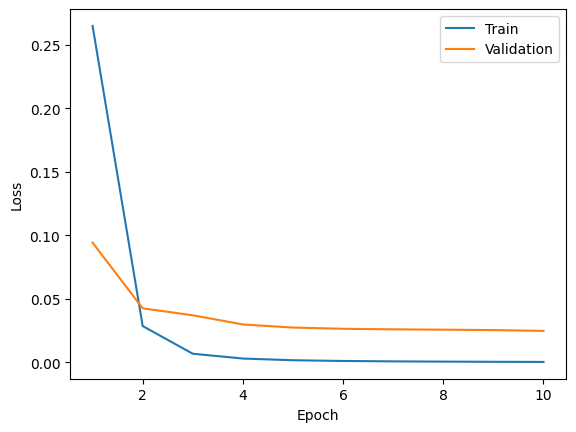

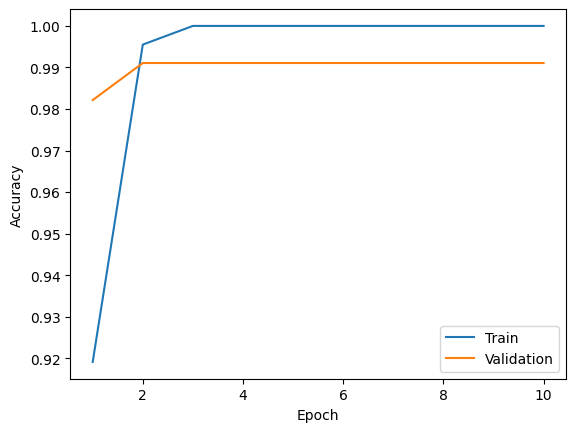

In [7]:
plt.plot(range(1, epochs+1), train_loss, label="Train")
plt.plot(range(1, epochs+1), val_loss, label="Validation")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()

plt.plot(range(1, epochs+1), train_acc, label="Train")
plt.plot(range(1, epochs+1), val_acc, label="Validation")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

### 6. Test ve başarı değerlendirmesi

Test loss: 0.05150079466402531
              precision    recall  f1-score   support

        cats       1.00      0.97      0.99        70
        dogs       0.97      1.00      0.99        70

    accuracy                           0.99       140
   macro avg       0.99      0.99      0.99       140
weighted avg       0.99      0.99      0.99       140



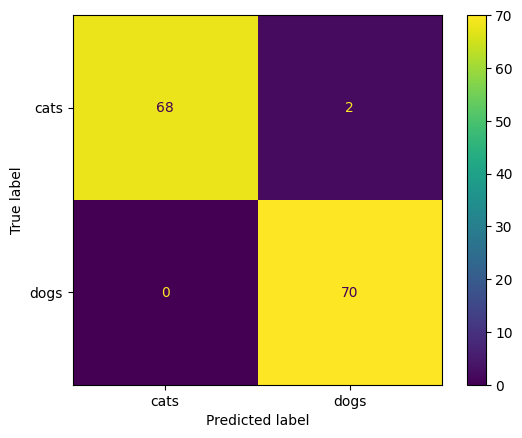

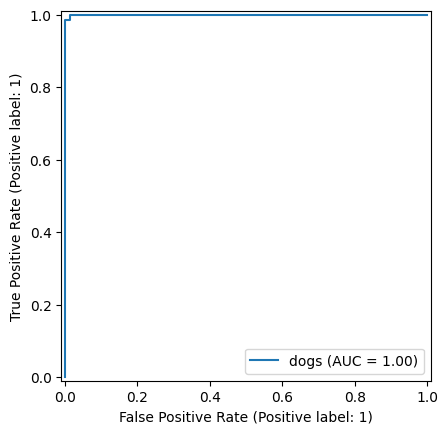

In [8]:
model.load_state_dict(torch.load("best_vit.pth", map_location=device))
model.eval()
y_true, y_pred, y_prob = [], [], []
loss_sum = 0
with torch.no_grad():
    for images, labels in test_loader:
        outputs = model(images.to(device))
        loss_sum += criterion(outputs, labels.to(device)).item() * labels.size(0)
        y_true.extend(labels.tolist())
        y_pred.extend(outputs.argmax(1).cpu().tolist())
        y_prob.extend(outputs.softmax(1)[:, 1].cpu().tolist())

print("Test loss:", loss_sum / len(test_dataset))
print(classification_report(y_true, y_pred, labels=[0, 1], target_names=class_names, zero_division=0))
ConfusionMatrixDisplay.from_predictions(y_true, y_pred, labels=[0, 1], display_labels=class_names)
plt.show()
RocCurveDisplay.from_predictions(y_true, y_prob, pos_label=1, name=class_names[1])
plt.show()

###7. Örnek test tahminleri

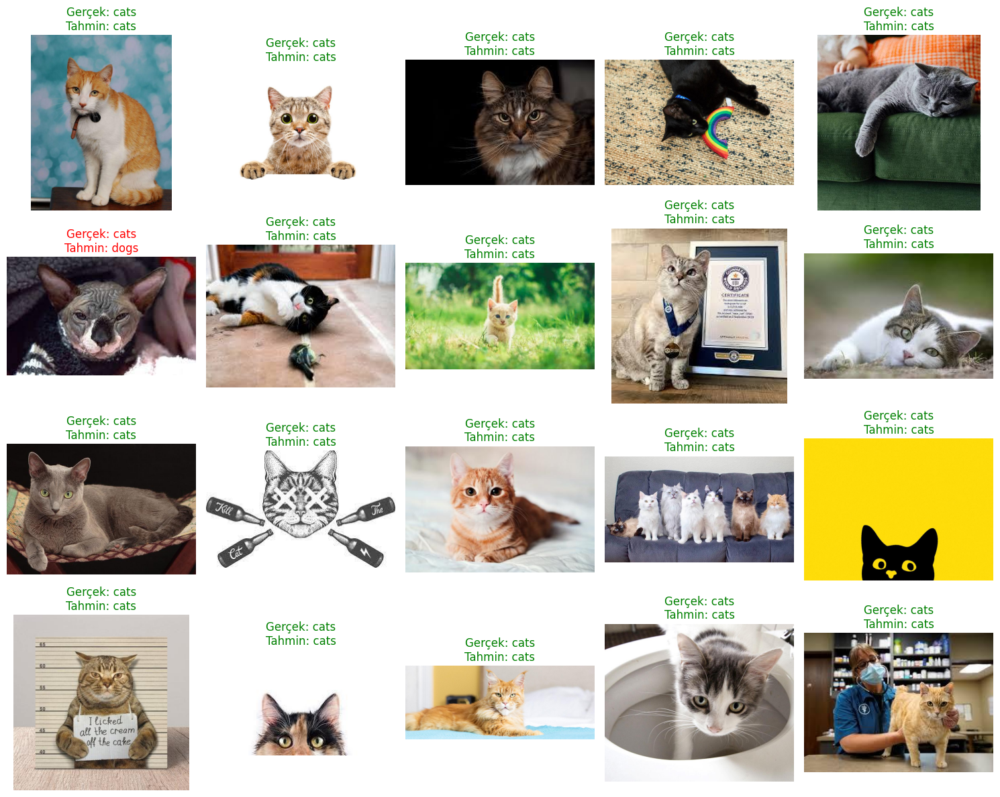

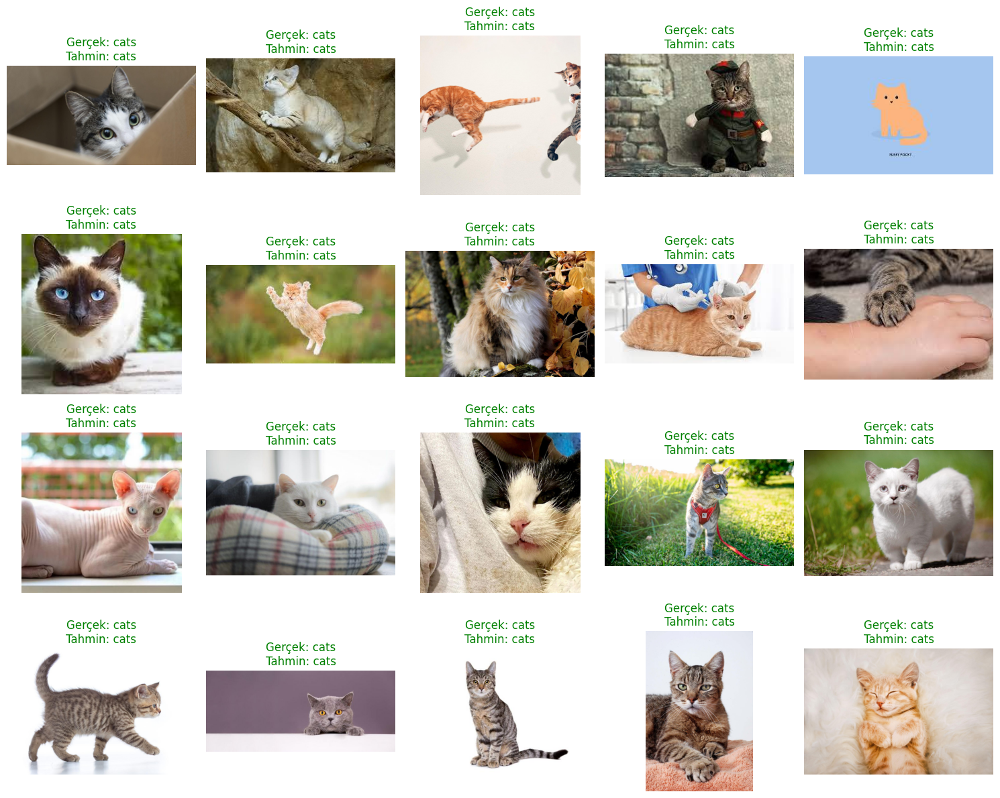

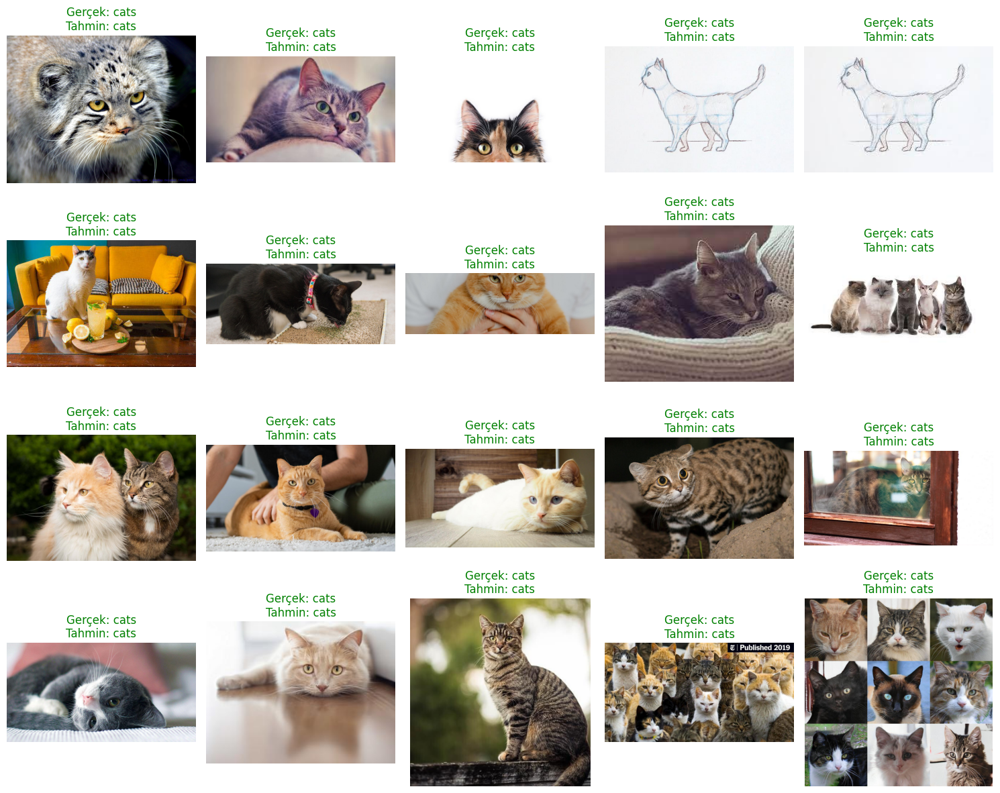

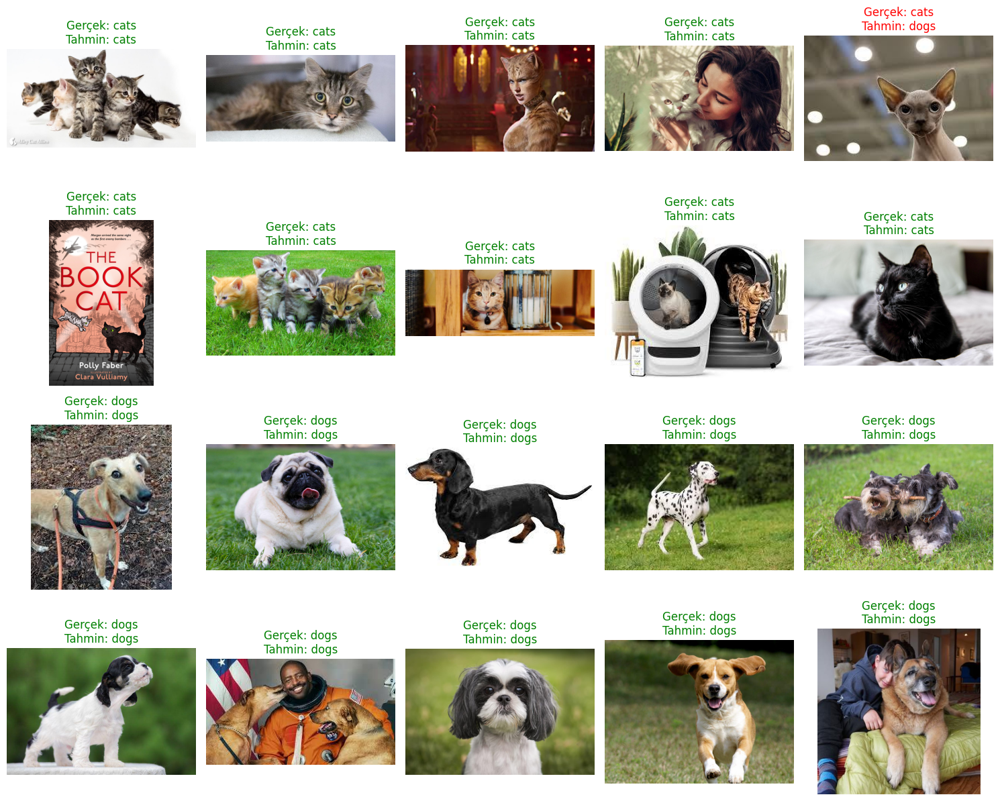

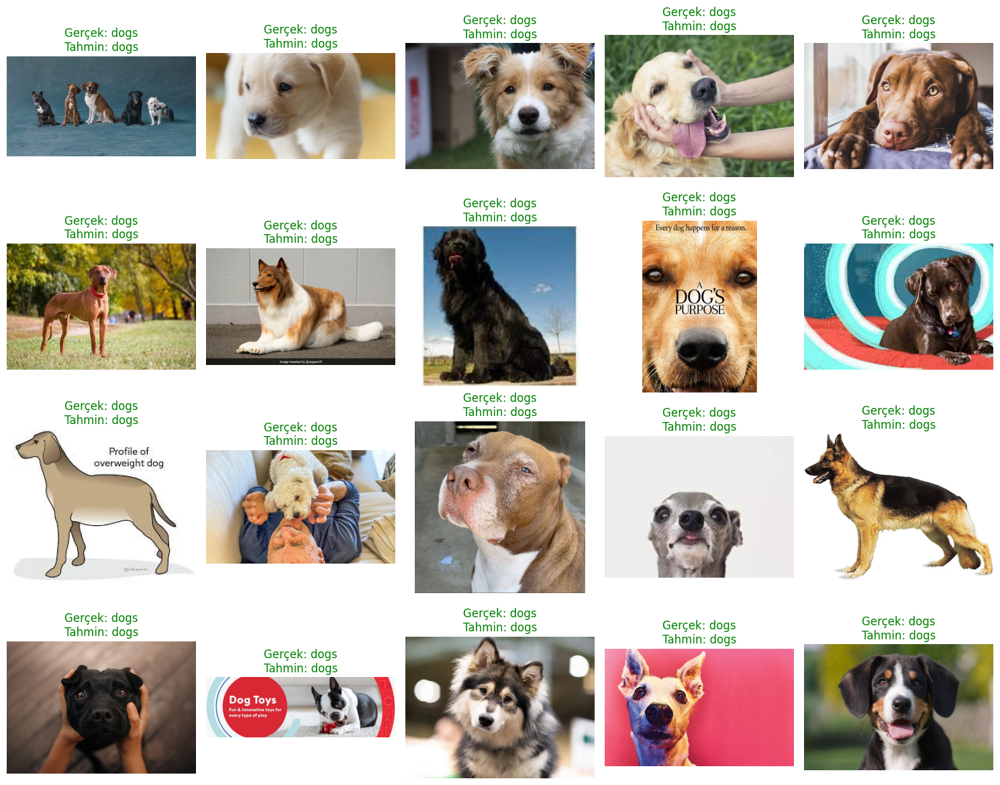

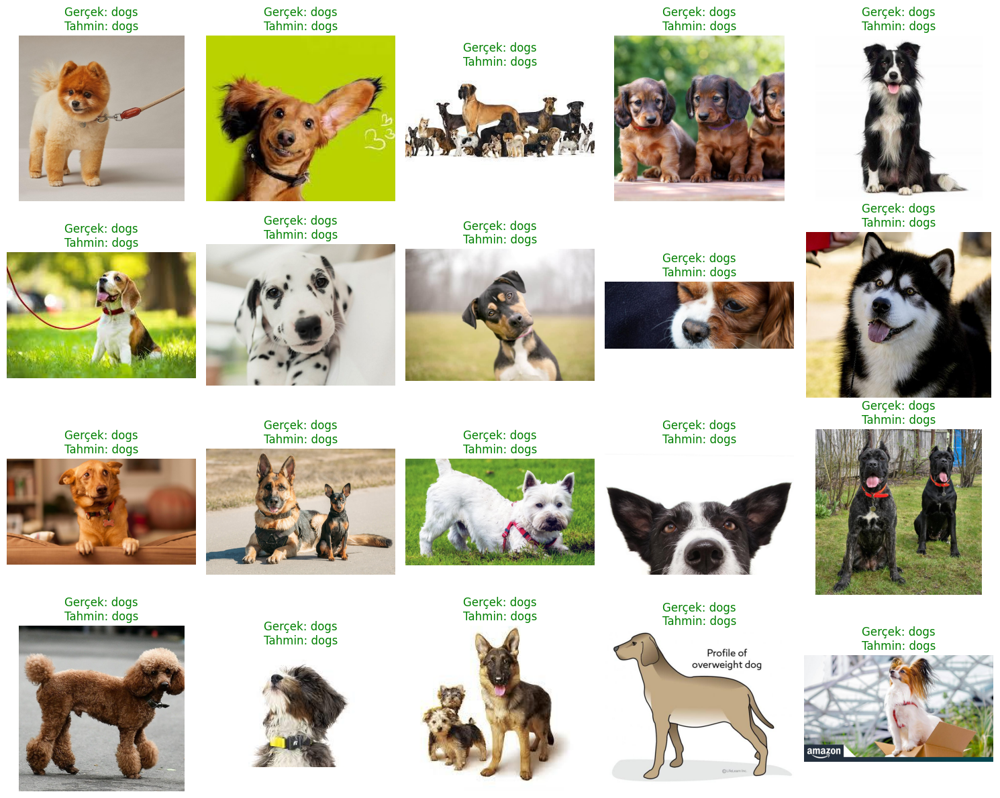

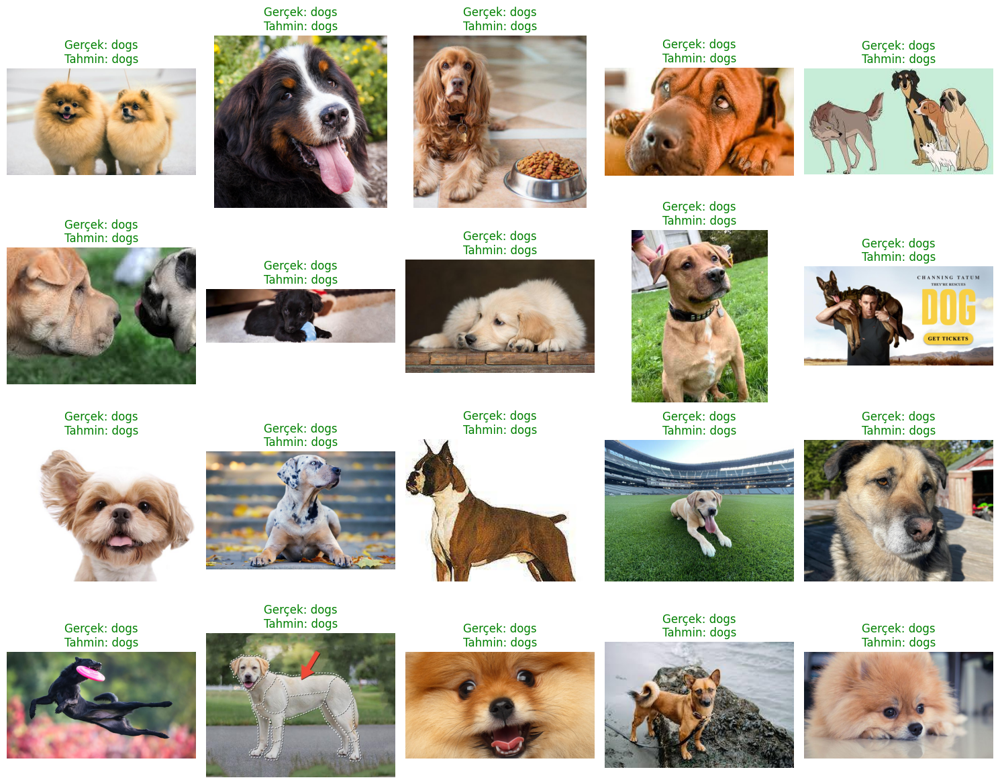

In [15]:
model.eval()

for start in range(0, len(test_dataset), 20):

    plt.figure(figsize=(15, 12))

    for j, i in enumerate(range(start, min(start + 20, len(test_dataset)))):

        image_path, label = test_dataset.samples[i]
        image = test_dataset.loader(image_path)

        with torch.no_grad():
            pred = model(transform(image).unsqueeze(0).to(device)).argmax(1).item()

        plt.subplot(4, 5, j + 1)
        plt.imshow(image)

        plt.title(
            f"Gerçek: {class_names[label]}\n"
            f"Tahmin: {class_names[pred]}",
            color="green" if label == pred else "red"
        )

        plt.axis("off")

    plt.tight_layout()
    plt.show()